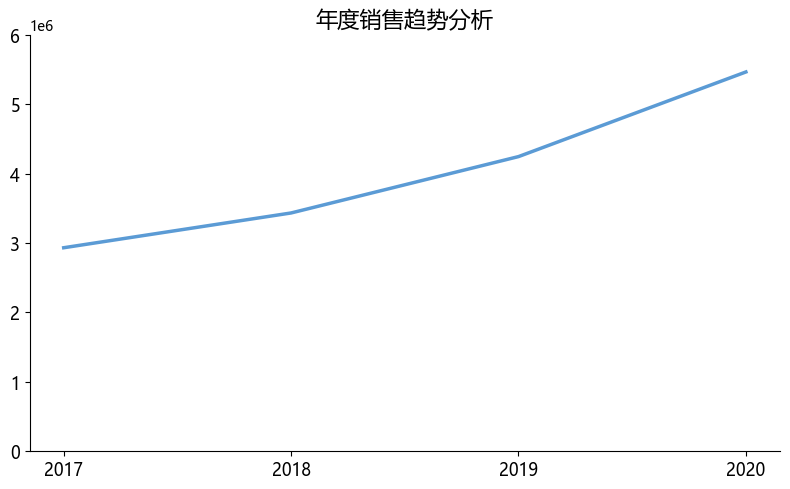

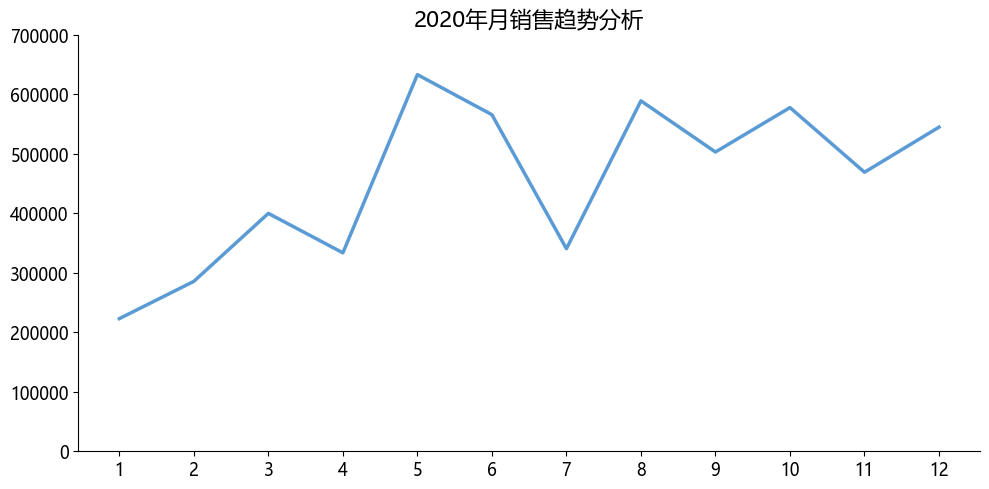

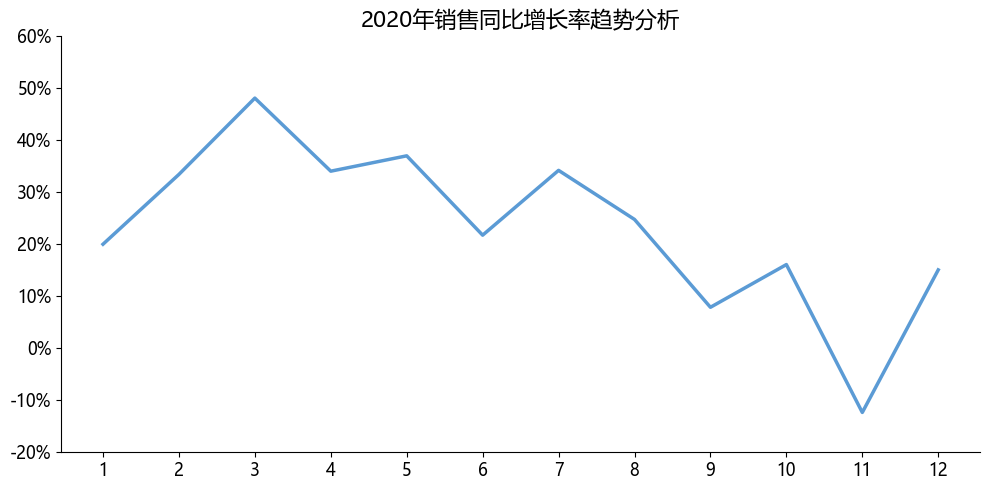

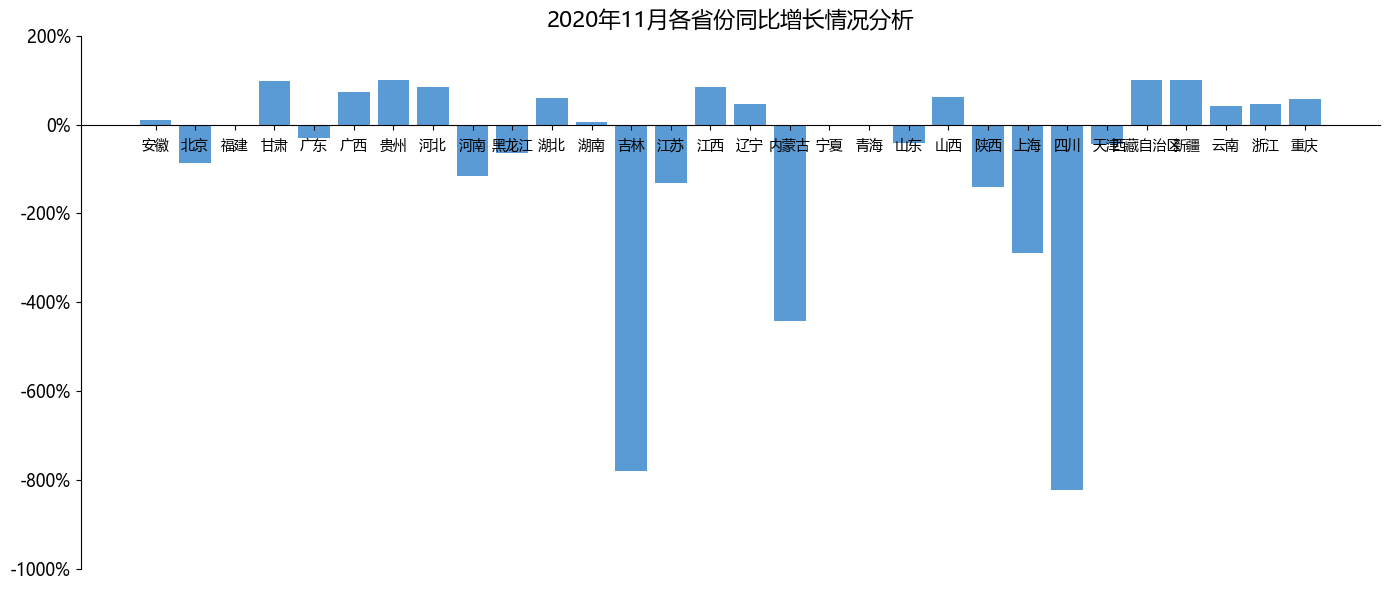

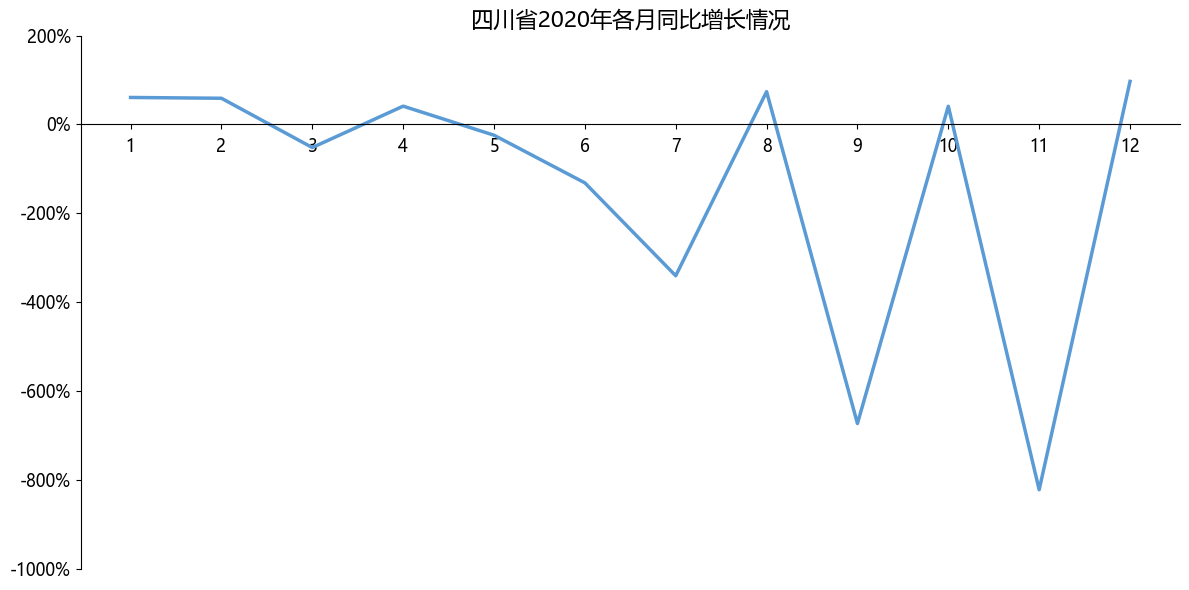

In [4]:
#第三章————案例一
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# ========== 1. 读取原始数据 ==========
file_path = '案例1：收入趋势分析案例-完整.xlsx'
df = pd.read_excel(file_path, sheet_name='原始数据')
df.columns = [c.strip() for c in df.columns]

df['订单年份'] = df['订单年份'].astype(int)
df['订单月份'] = df['订单月份'].astype(int)
df['销售额'] = df['销售额'].astype(float)

# ========== 2. 图1：年度销售趋势分析 ==========
year_sales = df.groupby('订单年份')['销售额'].sum().reset_index()
year_sales = year_sales.sort_values('订单年份')

plt.figure(figsize=(8, 5))
plt.plot(year_sales['订单年份'].astype(str), year_sales['销售额'],
         color='#5B9BD5', linewidth=2.5)
plt.title('年度销售趋势分析', fontsize=16)
plt.ylim(0, 6000000)
plt.yticks(np.arange(0, 6000001, 1000000))
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# ========== 3. 图2：2020年月销售趋势分析 ==========
month_2020 = df[df['订单年份'] == 2020].groupby('订单月份')['销售额'].sum().reset_index()
month_2020 = month_2020.set_index('订单月份').reindex(range(1, 13), fill_value=0).reset_index()

plt.figure(figsize=(10, 5))
plt.plot(month_2020['订单月份'].astype(str), month_2020['销售额'],
         color='#5B9BD5', linewidth=2.5)
plt.title('2020年月销售趋势分析', fontsize=16)
plt.ylim(0, 700000)
plt.yticks(np.arange(0, 700001, 100000))
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# ========== 4. 图3：2020年销售同比增长率趋势分析 ==========
df_yoy = df[df['订单年份'].isin([2019, 2020])]
month_yoy = df_yoy.pivot_table(index='订单月份', columns='订单年份',
                               values='销售额', aggfunc='sum', fill_value=0)
month_yoy = month_yoy.reindex(index=range(1, 13), fill_value=0)
month_yoy = month_yoy.reindex(columns=[2019, 2020], fill_value=0)

month_yoy['同比增长率'] = (month_yoy[2020] - month_yoy[2019]) / month_yoy[2020].replace(0, np.nan)
month_yoy['同比增长率'] = month_yoy['同比增长率'].fillna(0)

plt.figure(figsize=(10, 5))
plt.plot(month_yoy.index.astype(str), month_yoy['同比增长率'] * 100,
         color='#5B9BD5', linewidth=2.5)
plt.title('2020年销售同比增长率趋势分析', fontsize=16)
plt.ylim(-20, 60)
plt.yticks(np.arange(-20, 61, 10), [f'{x}%' for x in np.arange(-20, 61, 10)])
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# ========== 图4：2020年11月各省份同比增长情况分析 ==========
nov = df[(df['订单月份'] == 11) & (df['订单年份'].isin([2019, 2020]))]
nov_pivot = nov.pivot_table(index='销售省份', columns='订单年份',
                            values='销售额', aggfunc='sum', fill_value=0)
nov_pivot = nov_pivot.reindex(columns=[2019, 2020], fill_value=0)

# 准备区公式：=(2020-2019)/2020
nov_pivot['同比增长率'] = (nov_pivot[2020] - nov_pivot[2019]) / nov_pivot[2020].replace(0, np.nan)
nov_pivot['同比增长率'] = nov_pivot['同比增长率'].fillna(0)

province_order = ['安徽', '北京', '福建', '甘肃', '广东', '广西', '贵州', '河北', '河南', '黑龙江',
                  '湖北', '湖南', '吉林', '江苏', '江西', '辽宁', '内蒙古', '宁夏', '青海', '山东',
                  '山西', '陕西', '上海', '四川', '天津', '西藏自治区', '新疆', '云南', '浙江', '重庆']
nov_pivot = nov_pivot.reindex(province_order).fillna(0)

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(nov_pivot.index, nov_pivot['同比增长率'] * 100, color='#5B9BD5')

ax.set_title('2020年11月各省份同比增长情况分析', fontsize=16)
ax.set_ylim(-1000, 200)
ax.set_yticks(np.arange(-1000, 201, 200))
ax.set_yticklabels([f'{x}%' for x in np.arange(-1000, 201, 200)], fontsize=12)

ax.set_xticks(range(len(nov_pivot.index)))
ax.set_xticklabels(nov_pivot.index, rotation=45, ha='right', fontsize=10)

# ===== 关键修改：让横坐标轴和省份标签跟着 y=0 走 =====
ax.spines['bottom'].set_position(('data', 0))      # 把 x 轴移动到 y=0 处
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# x 轴标签放到 0 线下方一点，避免压住柱子
ax.tick_params(axis='x', direction='out', pad=6, labelsize=10,
               bottom=True, labelbottom=True)

plt.tight_layout()
plt.show()

# ========== 图5：四川省2020年各月同比增长情况 ==========
sc = df[(df['销售省份'] == '四川') & (df['订单年份'].isin([2019, 2020]))]
sc_pivot = sc.pivot_table(index='订单月份', columns='订单年份',
                          values='销售额', aggfunc='sum', fill_value=0)
sc_pivot = sc_pivot.reindex(index=range(1, 13), fill_value=0)
sc_pivot = sc_pivot.reindex(columns=[2019, 2020], fill_value=0)

# 准备区公式：=(2020-2019)/2020
sc_pivot['同比增长率'] = (sc_pivot[2020] - sc_pivot[2019]) / sc_pivot[2020].replace(0, np.nan)
sc_pivot['同比增长率'] = sc_pivot['同比增长率'].fillna(0)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(sc_pivot.index.astype(str), sc_pivot['同比增长率'] * 100,
        color='#5B9BD5', linewidth=2.5)

ax.set_title('四川省2020年各月同比增长情况', fontsize=16)
ax.set_ylim(-1000, 200)
ax.set_yticks(np.arange(-1000, 201, 200))
ax.set_yticklabels([f'{x}%' for x in np.arange(-1000, 201, 200)], fontsize=12)

# ===== 关键修改：让横坐标轴和月份标签跟着 y=0 走 =====
ax.spines['bottom'].set_position(('data', 0))   # x 轴移动到 y=0 处
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.tick_params(axis='x', direction='out', pad=6, labelsize=12,
               bottom=True, labelbottom=True)

plt.tight_layout()
plt.show()

C:\Users\21409\AppData\Local\Temp\ipykernel_8308\1319347369.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['6月', '7月'], fontsize=12)


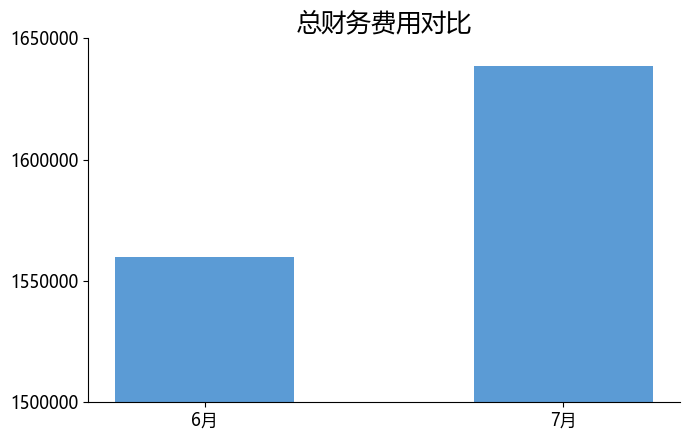

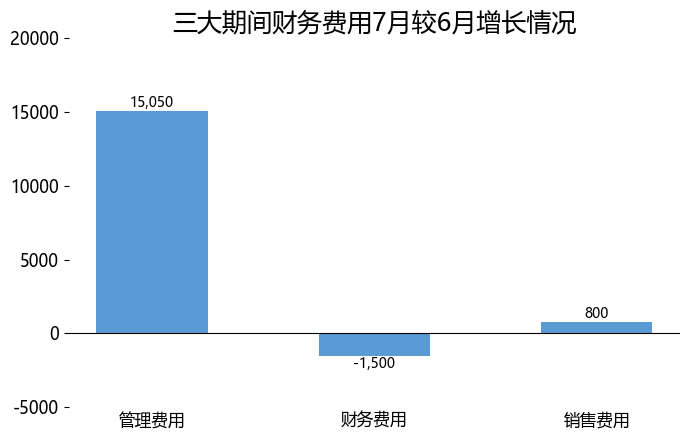

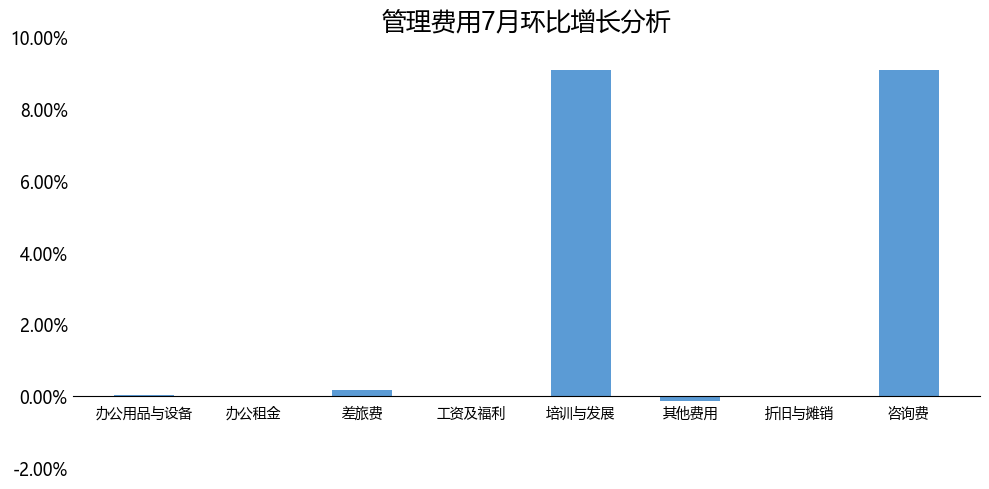

In [9]:
#第三章————案例二
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 中文字体设置
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# ========== 读取原始数据 ==========
file_path = '案例2：财务费用分析-完整案例.xlsx'

df_total = pd.read_excel(file_path, sheet_name='总费用数据-原始数据')
df_period = pd.read_excel(file_path, sheet_name='财务三大期间费用-原始数据')
df_admin = pd.read_excel(file_path, sheet_name='管理费用-原始数据')

df_period['月份'] = df_period['月份'].astype(int)
df_admin['月份'] = df_admin['月份'].astype(int)

# ============================================================
# 图1：总财务费用对比（Y轴从1500000起，不从0起）
# ============================================================
total_6 = df_total[df_total['月份'] == '6月']['金额'].values[0]
total_7 = df_total[df_total['月份'] == '7月']['金额'].values[0]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(['6月', '7月'], [total_6, total_7],
              color='#5B9BD5', width=0.5)

ax.set_title('总财务费用对比', fontsize=18)
ax.set_ylim(1500000, 1650000)
ax.set_yticks([1500000, 1550000, 1600000, 1650000])
ax.set_yticklabels(['1500000', '1550000', '1600000', '1650000'], fontsize=12)
ax.set_xticklabels(['6月', '7月'], fontsize=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# ============================================================
# 图2：三大期间财务费用7月较6月增长情况（环比差额）
# ============================================================
# 复制一份，避免污染原数据
tmp = df_period.copy()
tmp['期间费用项'] = tmp['期间费用项'].astype(str).str.strip()
tmp['月份'] = tmp['月份'].astype(int)

pivot_period = tmp.pivot_table(index='期间费用项', columns='月份',
                               values='金额', aggfunc='sum')
pivot_period = pivot_period.reindex(columns=[6, 7], fill_value=0)
pivot_period['环比差额'] = pivot_period[7] - pivot_period[6]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(pivot_period.index, pivot_period['环比差额'],
              color='#5B9BD5', width=0.5)

# 为每个柱子标数值，方便确认
for bar, v in zip(bars, pivot_period['环比差额']):
    if v >= 0:
        ax.text(bar.get_x() + bar.get_width()/2, v,
                f'{v:,.0f}', ha='center', va='bottom', fontsize=10)
    else:
        ax.text(bar.get_x() + bar.get_width()/2, v,
                f'{v:,.0f}', ha='center', va='top', fontsize=10)

ax.set_title('三大期间财务费用7月较6月增长情况', fontsize=18)
ax.set_ylim(-5000, 20000)
ax.set_yticks([-5000, 0, 5000, 10000, 15000, 20000])
ax.set_yticklabels(['-5000', '0', '5000', '10000', '15000', '20000'], fontsize=12)
ax.tick_params(axis='x', labelsize=12)

# 横坐标轴在 y=0 处
ax.axhline(0, color='black', linewidth=0.8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.tick_params(axis='x', length=0)

plt.tight_layout()
plt.show()

# ============================================================
# 图3：管理费用7月环比增长分析（按明细项，横坐标轴在0%处）
# ============================================================
pivot_admin = df_admin.pivot_table(index='管理费用项', columns='月份',
                                   values='金额', aggfunc='sum')
pivot_admin = pivot_admin.reindex(columns=[6, 7], fill_value=0)
pivot_admin['环比增长'] = (pivot_admin[7] - pivot_admin[6]) / pivot_admin[6] * 100

# 顺序按准备区：办公用品与设备、办公租金、差旅费、工资及福利、
#               培训与发展、其他费用、折旧与摊销、咨询费
order3 = ['办公用品与设备', '办公租金', '差旅费', '工资及福利',
          '培训与发展', '其他费用', '折旧与摊销', '咨询费']
pivot_admin = pivot_admin.reindex(order3)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(pivot_admin.index, pivot_admin['环比增长'],
              color='#5B9BD5', width=0.55)

ax.set_title('管理费用7月环比增长分析', fontsize=18)
ax.set_ylim(-2, 10)
ax.set_yticks(np.arange(-2, 11, 2))
ax.set_yticklabels([f'{x:.2f}%' for x in np.arange(-2, 11, 2)], fontsize=12)

ax.set_xticks(range(len(pivot_admin.index)))
ax.set_xticklabels(pivot_admin.index, rotation=45, ha='right', fontsize=12)

# 横坐标轴移到 y=0
ax.spines['bottom'].set_position(('data', 0))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

# 去掉刻度线，但保留标签
ax.tick_params(axis='x', length=0, pad=6, labelbottom=True)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

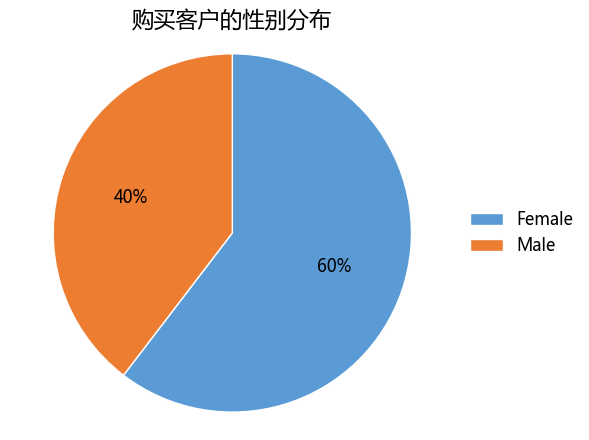

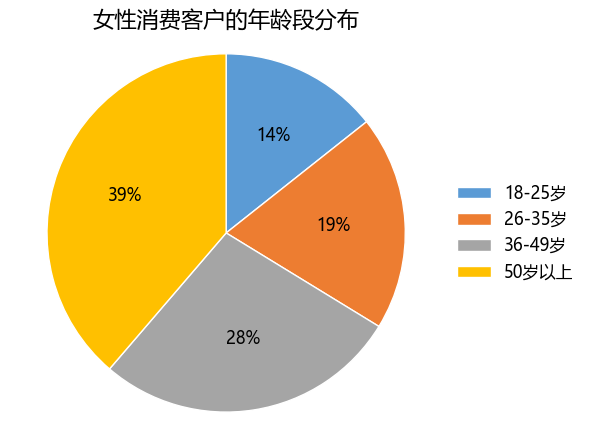

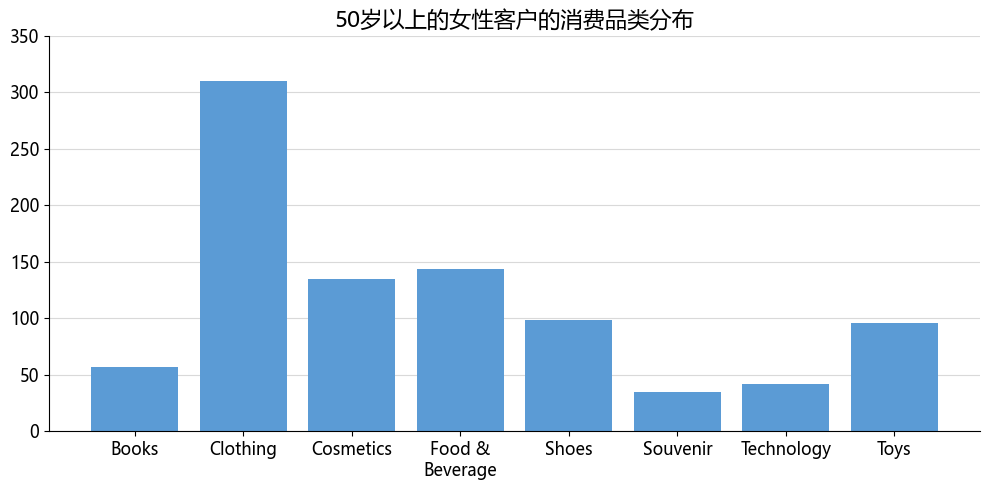

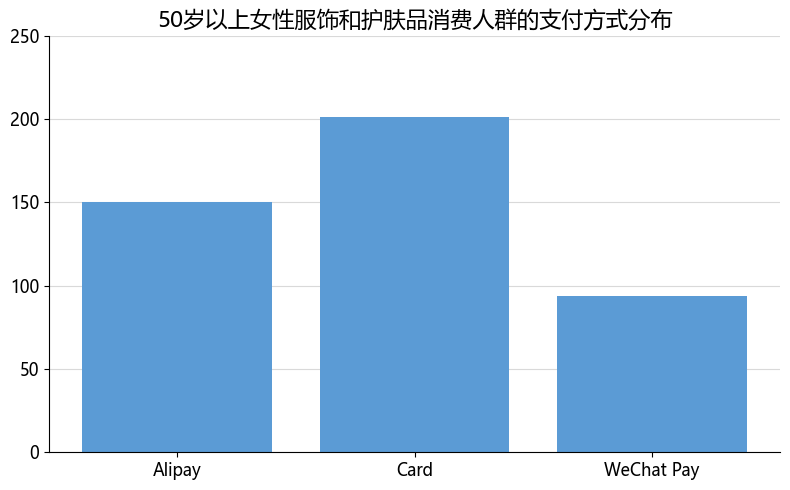

In [11]:
#第三章————案例三
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# ========== 1. 读取原始数据 ==========
file_path = '案例3：电商平台的精准营销-完整案例.xlsx'   # 如果不在当前目录，改成绝对路径
df = pd.read_excel(file_path, sheet_name='原始数据')
df.columns = [str(c).strip() for c in df.columns]

# 只保留需要的列，并做类型清洗
df = df[['客户ID', '性别', '年龄', '品类', '支付方式']].copy()
df['年龄'] = pd.to_numeric(df['年龄'], errors='coerce')
df = df.dropna(subset=['年龄']).copy()
df['年龄'] = df['年龄'].astype(int)

# 根据年龄计算年龄段（和准备区公式一致）
def age_group(age):
    if 18 <= age <= 25:
        return '18-25岁'
    elif 26 <= age <= 35:
        return '26-35岁'
    elif 36 <= age <= 49:
        return '36-49岁'
    else:
        return '50岁以上'

df['年龄段'] = df['年龄'].apply(age_group)

# ============================================================
# 图1：购买客户的性别分布
# ============================================================
gender_counts = df['性别'].value_counts().reindex(['Female', 'Male'])
labels1 = ['Female', 'Male']
colors1 = ['#5B9BD5', '#ED7D31']

plt.figure(figsize=(6, 4.5))
plt.pie(
    gender_counts.values,
    labels=None,
    autopct='%1.0f%%',
    colors=colors1,
    startangle=90,
    counterclock=False,
    wedgeprops={'edgecolor': 'white'},
    textprops={'fontsize': 12}
)
plt.title('购买客户的性别分布', fontsize=16)
plt.legend(labels1, loc='center left', bbox_to_anchor=(1, 0.5), frameon=False, fontsize=12)
plt.axis('equal')
plt.tight_layout()
plt.show()


# ============================================================
# 图2：女性消费客户的年龄段分布
# ============================================================
age_counts = female_df['年龄段'].value_counts().reindex(
    ['18-25岁', '26-35岁', '36-49岁', '50岁以上']
)
labels2 = ['18-25岁', '26-35岁', '36-49岁', '50岁以上']
colors2 = ['#5B9BD5', '#ED7D31', '#A5A5A5', '#FFC000']

plt.figure(figsize=(6, 4.5))
plt.pie(
    age_counts.values,
    labels=None,
    autopct='%1.0f%%',
    colors=colors2,
    startangle=90,
    counterclock=False,
    wedgeprops={'edgecolor': 'white'},
    textprops={'fontsize': 12}
)
plt.title('女性消费客户的年龄段分布', fontsize=16)
plt.legend(labels2, loc='center left', bbox_to_anchor=(1, 0.5), frameon=False, fontsize=12)
plt.axis('equal')
plt.tight_layout()
plt.show()


# ============================================================
# 图3：50岁以上的女性客户的消费品类分布
# ============================================================
cat_order = ['Books', 'Clothing', 'Cosmetics', 'Food & Beverage',
             'Shoes', 'Souvenir', 'Technology', 'Toys']
cat_counts = df_50_female['品类'].value_counts().reindex(cat_order)
cat_labels = ['Books', 'Clothing', 'Cosmetics', 'Food &\nBeverage',
              'Shoes', 'Souvenir', 'Technology', 'Toys']

plt.figure(figsize=(10, 5))
plt.bar(cat_labels, cat_counts.values, color='#5B9BD5')
plt.title('50岁以上的女性客户的消费品类分布', fontsize=16)
plt.ylim(0, 350)
plt.yticks(np.arange(0, 351, 50), fontsize=12)
plt.xticks(fontsize=12)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', color='#D9D9D9', linestyle='-', linewidth=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


# ============================================================
# 图4：50岁以上女性服饰和护肤品消费人群的支付方式分布
# ============================================================
pay_order = ['Alipay', 'Card', 'WeChat Pay']
pay_counts = df_50_female_fashion['支付方式'].value_counts().reindex(pay_order)

plt.figure(figsize=(8, 5))
plt.bar(pay_counts.index, pay_counts.values, color='#5B9BD5')
plt.title('50岁以上女性服饰和护肤品消费人群的支付方式分布', fontsize=16)
plt.ylim(0, 250)
plt.yticks(np.arange(0, 251, 50), fontsize=12)
plt.xticks(fontsize=12)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', color='#D9D9D9', linestyle='-', linewidth=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()